In [1]:
# =============================================================================
# Created By:     Kai Metzger
# Created School: Franz-Oberthuer-Schule Wuerzburg
# Created Email:  metzgerkai@franz-oberthuer-schule.de
# Created Date:   Tue Nov 17 20:54 UTC 2026
# Version:        1.1.0
# =============================================================================
"""The Module has been build for training the symbols dataset with images + 
ground truth on a Raspberry Pi 5 with a standard USB camera. An image with a 
resolution of 0.3MPixel to 2MP can be recorded with the Python script 
create-symbols-dataset.py
Files:
- 00 data-info.ipynb shows the data count per dataset.
- 01 create-symbols-dataset.py (camera needed)
- 02 training scripts
- 03 detect-symbols.ipynb

"""

# =============================================================================
# Import
# =============================================================================
import cv2
import os
import numpy as np
from pathlib import Path
from keras import layers, models, utils, callbacks
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import splitfolders

# Enable Nvidia GPUs by un-commenting this line 
os.environ['CUDA_VISIBLE_DEVICES'] = "0"
XLA_FLAGS="--xla_gpu_cuda_data_dir=/usr/"

# To get reproducable results with the same training setting random seed
SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

DEBUG = True

In [2]:
# =============================================================================
# Declare variables / dataset
# =============================================================================
# Change the following paths to your dataset path
home_dir = os.path.expanduser("~")

dataset = ""                                            # CHANGE DATASET NUMBER

dataset_for_training = "dataset" + str(dataset)  
dataset_for_training_split = dataset_for_training + "-split70-15-15"
checkpoint_filepath = home_dir + "/ml_project/datasets/symbols/" + "chpt/"
print(dataset_for_training)
print(checkpoint_filepath)

dataset
/home/pi/ml_project/datasets/symbols/chpt/


In [3]:
# =============================================================================
# Split into 70% train, 15% val, 15% test on disk
# =============================================================================
source_dir = Path(dataset_for_training_split)
split_dir = source_dir.parent / f"{source_dir.name}"

if not split_dir.exists():
    splitfolders.ratio(
        input=str(dataset_for_training),
        output=str(split_dir),
        shuffle=True,
        seed=SEED,
        ratio=(0.70, 0.15, 0.15),
    )
else:
    print(f"Split folder already exists; skipping: {split_dir}")

Split folder already exists; skipping: dataset-split70-15-15


In [4]:
# =============================================================================
# Dataset related parameters
# =============================================================================
NUM_CLASSES = 4
IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)
IMG_CHANNELS = 3                                       # 1=:grayscale, 3=:color
INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)

# =============================================================================
# Hyperparameters
# =============================================================================
BATCH_SIZE = 32
EPOCHS = 300

In [5]:
# =============================================================================
# Load dataset
# =============================================================================
split = "train-val-test"   # or: "train-val-test"

if split == "train-val":
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training,
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        shuffle=True,
        validation_split=0.3,
        subset="training",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )

    validation_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training,
        labels="inferred",
        label_mode="categorical",
        shuffle=False,
        validation_split=0.3,
        subset="validation",
        seed=SEED,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE
    )
elif split == "train-val-test":
    # Load each directory directly
    train_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/train", 
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        shuffle=True,
        seed=SEED,
        image_size=IMG_SIZE, 
        batch_size=BATCH_SIZE
    )
    validation_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/val", 
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        seed=SEED,
        image_size=IMG_SIZE, 
        batch_size=BATCH_SIZE
    )
    test_dataset = tf.keras.utils.image_dataset_from_directory(
        dataset_for_training_split + "/test", 
        labels="inferred",
        label_mode="categorical",                           # 4 Klassen → 1-hot
        seed=SEED,
        image_size=IMG_SIZE, 
        batch_size=BATCH_SIZE
    )

Found 1213 files belonging to 4 classes.
Found 258 files belonging to 4 classes.
Found 264 files belonging to 4 classes.


In [6]:
# =============================================================================
# Class names
# =============================================================================
class_names = train_dataset.class_names #CLASS_NAMES = ["0", "1", "2", "3"]
NUM_CLASSES = len(class_names)
print("Klassen:", class_names, "\n")

Klassen: ['0', '1', '2', '3'] 



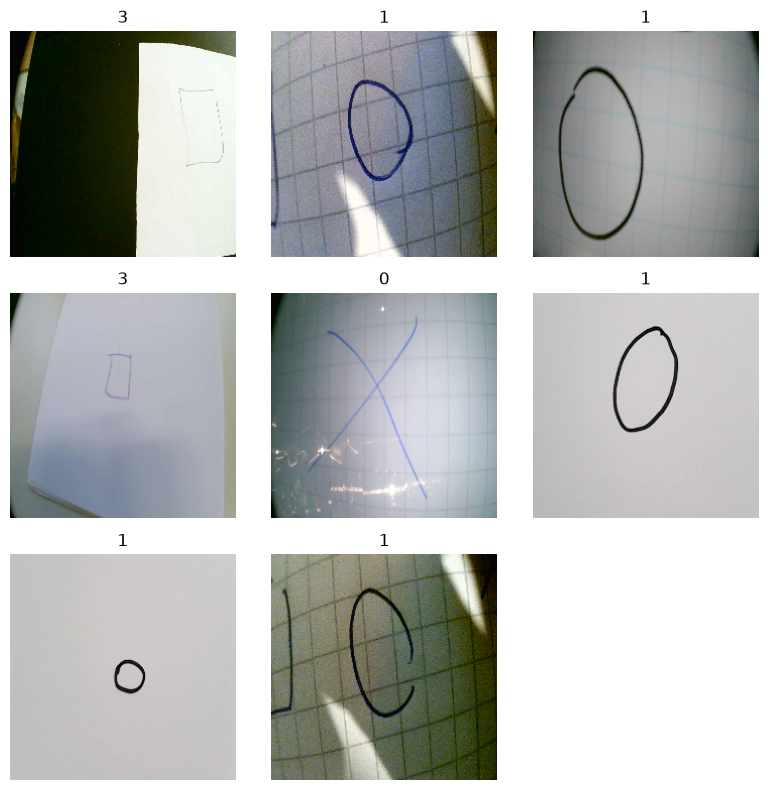

In [ ]:
# =============================================================================
# Preview 9 training images
# =============================================================================
plt.figure(figsize=(8, 8))
for images, labels in train_dataset.take(1):
    for i in range( min(BATCH_SIZE, 9)): # choose minimum of batch size and a nuber
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))        
        label_index = labels[i].numpy().argmax()
        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()

In [8]:
# =============================================================================
# Prefetch data:
# It prepares the next batch while the model works on the current one, which 
# can improve training speed. It doesn’t split data or change the labels. 
# AUTOTUNE lets TensorFlow choose how much to prefetch, but it may use more 
# RAM. On a memory-constrained Raspberry Pi, try limiting it to one batch:
# =============================================================================
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

print('Number of training batches: %d' % tf.data.experimental.cardinality(train_dataset))
print('Number of validation batches: %d' % tf.data.experimental.cardinality(validation_dataset))
print('Number of test batches: %d' % tf.data.experimental.cardinality(test_dataset))

Number of training batches: 38
Number of validation batches: 9
Number of test batches: 9


In [9]:
# =============================================================================
# Data Augmentation
# =============================================================================
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(factor=0.1),
    layers.RandomZoom(0.05),   
])

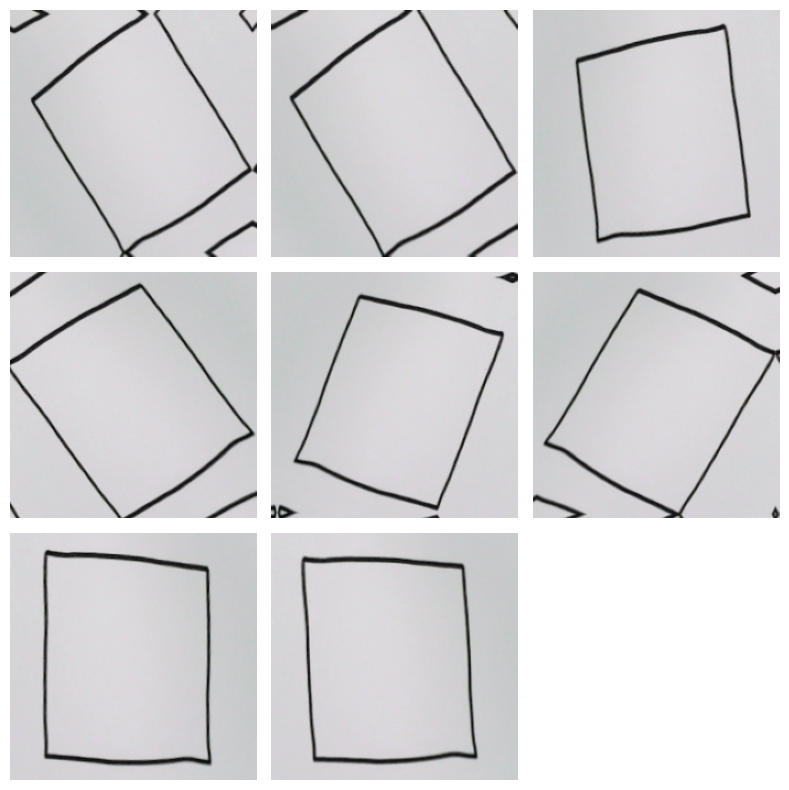

In [ ]:
# =============================================================================
# Check images for training
# =============================================================================
for image, _ in train_dataset.take(1):
  # Display the original image and 9 augmented versions
  plt.figure(figsize=(8, 8))
  first_image = image[0]
  for i in range( min(BATCH_SIZE, 9)):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

plt.tight_layout()

In [ ]:
# =============================================================================
# Create neural network with 1, 2, ..., L layers 
# and (64, 32, 16, 4) filters per layer.
# =============================================================================
model = models.Sequential()

model_name = "small"
if model_name == "small":
    model = models.Sequential([
        # INPUT LAYER
        layers.Input(shape=INPUT_SHAPE),

        # Add rescaling here if pixel values are in [0, 255].
        layers.Rescaling(1./255),
        
        # For RGB input, you can optionally convert to grayscale:
        # layers.Lambda(tf.image.rgb_to_grayscale),

        # DATA AUGMENTATION
        data_augmentation,

        # HIDDEN LAYER 1: 32 filters
        layers.Conv2D(filters=16, kernel_size=3, padding='same', 
                      activation='relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),

        # HIDDEN LAYER 2: 128 filters
        layers.Conv2D(32, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(), 

        # HIDDEN LAYER 2: 128 filters
        layers.Conv2D(64, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),          
        
        # HIDDEN LAYER 2: 128 filters
        layers.Conv2D(128, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),  

        # HIDDEN LAYER 3: 16 filters
        layers.Conv2D(16, 3, padding='same', activation='relu'),
        layers.MaxPooling2D(),

        # Vectorize the 2D feature maps into a 1D feature vector
        layers.Flatten(),

        # HIDDEN LAYER 4: Fully connected layer with 256 neurons
        layers.Dense(256,activation='relu'),
        layers.Dropout(0.3),        
        
        layers.Dense(32,activation='relu'),
        layers.Dropout(0.3),

        # OUTPUT LAYER
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ])
elif model_name ==  "lenet":
    model = models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        data_augmentation,
        # TODO
        # Add Rescaling(1./255) here if pixel values are in [0, 255].
        # For RGB input, you can optionally convert to grayscale:
        # layers.Lambda(tf.image.rgb_to_grayscale),

        layers.Conv2D(6, kernel_size=5, activation="tanh", padding="valid"),
        layers.AveragePooling2D(pool_size=2, strides=2),

        layers.Conv2D(16, kernel_size=5, activation="tanh", padding="valid"),
        layers.AveragePooling2D(pool_size=2, strides=2),

        layers.Flatten(),
        layers.Dense(120, activation="tanh"),
        layers.Dense(84, activation="tanh"),
        layers.Dense(4, activation="softmax"),
    ])

In [ ]:
# =============================================================================
# Take a look at our model
# =============================================================================
if debug:
    print(model.summary())

In [12]:
# =============================================================================
# HYPERPARAMETERS
# =============================================================================
LEARNING_RATE = 3e-4

lr = "fixed"                                                 # HYPERPARAMETER 4
if lr == "fixed":
    learning_rate = LEARNING_RATE 
elif lr == "decay":
    learning_rate = keras.optimizers.schedules.ExponentialDecay(
        initial_learning_rate=LEARNING_RATE,
        decay_steps=500, # 10% every 10 epochs = ???
        decay_rate=0.9
    )  
elif lr == "plateu":                                    
    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
    )


optimizer = "adam"                                           # HYPERPARAMETER 5
if optimizer == "adam":
    optimizer_fcn = keras.optimizers.Adam(learning_rate=learning_rate)
elif optimizer == "sgd":
    optimizer_fcn = keras.optimizers.SGD(learning_rate=learning_rate)
elif optimizer == "rmsprop":
    optimizer_fcn = keras.optimizers.RMSprop(learning_rate=learning_rate)
elif optimizer == "adagrad":
    optimizer_fcn = keras.optimizers.Adagrad(learning_rate=learning_rate)

loss_fcn = "categorical_crossentropy"       
#loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)                    
#loss = "sparse_categorical_crossentropy"
#loss = "mean_squared_error"
#...

metric_fcn = ["accuracy"]
#metric=["sparse_categorical_accuracy"]
#...

model.compile(
    loss=loss_fcn,
    optimizer=optimizer_fcn,
    metrics=metric_fcn,
)

In [14]:
# =============================================================================
# TensorBoard Logging
# =============================================================================
log_path = "logs/fit"
tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=log_path,
    histogram_freq=1
)

# Starten in Shell: tensorboard --logdir datasets/symbols/logs/fit

In [ ]:
# =============================================================================
# Early stopping after e.g. 10 epochs if loss does not improve
# =============================================================================
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
)

In [16]:
# =============================================================================
# Callback for training
# =============================================================================
from datetime import datetime
from pathlib import Path

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
checkpoint_dir = Path(checkpoint_filepath)
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_file = checkpoint_dir / f"chpt_{timestamp}.keras"

print(checkpoint_file)  # Should end with chpt_YYYYMMDD_HHMMSS.keras

# Set verbose flag to 0 to omit loss/accuracy output per epoch
checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_file),
    monitor='val_loss',       # metric to monitor
    save_best_only=True,      # only save when metric improves
    mode='auto',              # minimize loss and aximize accuracy
    verbose=0,                # Print a line when the model is saved
)

/home/pi/ml_project/datasets/symbols/chpt/chpt_20261118_183628.keras


In [17]:
# =============================================================================
# Train the neuronal network e.g. for some epochs.
# =============================================================================
history = model.fit(
    train_dataset, 
    validation_data=validation_dataset,
    epochs=EPOCHS, 
    verbose=1, 
    callbacks=[checkpoint, 
               early_stopping,
               tensorboard_callback,
               ])

Epoch 1/300


/home/pi/ml_project/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1795023394.023397    9497 cpu_allocator_impl.cc:82] Allocation of 102760448 exceeds 10% of free system memory.
W0000 00:00:1795023394.368765    9497 cpu_allocator_impl.cc:82] Allocation of 51380224 exceeds 10% of free system memory.
W0000 00:00:1795023396.067552    9498 cpu_allocator_impl.cc:82] Allocation of 51380224 exceeds 10% of free system memory.
W0000 00:00:1795023396.938335    9497 cpu_allocator_impl.cc:82] Allocation of 51380224 exceeds 10% of free system memory.
W0000 00:00:1795023396.939269    9497 cpu_allocator_impl.cc:82] Allocation of 102760448 exceeds 10% of free system memory.


38/38 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step - accuracy: 0.2795 - loss: 1.3867 - val_accuracy: 0.2519 - val_loss: 1.3864
Epoch 2/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 103s 3s/step - accuracy: 0.2473 - loss: 1.3881 - val_accuracy: 0.2597 - val_loss: 1.3854
Epoch 3/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 101s 3s/step - accuracy: 0.2564 - loss: 1.3863 - val_accuracy: 0.2907 - val_loss: 1.3860
Epoch 4/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 141s 3s/step - accuracy: 0.2704 - loss: 1.3847 - val_accuracy: 0.2868 - val_loss: 1.3815
Epoch 5/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.2556 - loss: 1.3846 - val_accuracy: 0.3721 - val_loss: 1.3741
Epoch 6/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.3157 - loss: 1.3649 - val_accuracy: 0.3760 - val_loss: 1.3377
Epoch 7/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 142s 3s/step - accuracy: 0.3479 - loss: 1.3432 - val_accuracy: 0.3992 - val_loss: 1.2649
Epoch 8/300
38/38 ━━━━━━━━━━━━━━━━━━━━ 100s 3s/step - accuracy: 0.3735 - loss: 1.2972 - val_accuracy: 0.4419 - val_l

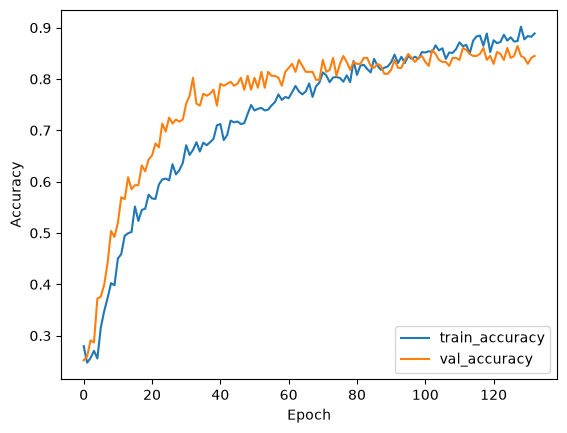

In [18]:
# =============================================================================
# Plot train and val accuracy.
# =============================================================================

plt.plot(history.history['accuracy'], label='train_accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.show()


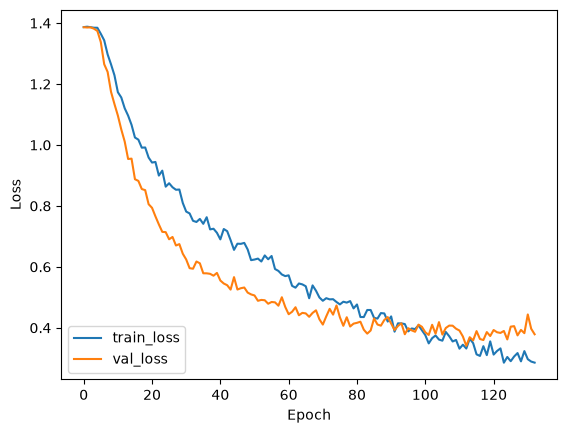

In [19]:
# =============================================================================
# Plot train and val loss.
# =============================================================================

plt.plot(history.history['loss'], label='train_loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='lower left')
plt.show()

In [20]:
# =============================================================================
# Load pretrained dataset weights to e.g. test on new (unseen) data.
# =============================================================================
model.load_weights(str(checkpoint_file))

In [21]:
# =============================================================================
# Test Accuracy on test set
# =============================================================================
results = model.evaluate(test_dataset, 
                         verbose=1, 
                         return_dict=True,
                         )

loss = results["loss"]
accuracy = results.get("accuracy")  # available if you compiled with an accuracy metric

print("Test loss:", loss)
print("Test accuracy:", accuracy)

9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 478ms/step - accuracy: 0.7992 - loss: 0.5096
Test loss: 0.5096427202224731
Test accuracy: 0.7992424368858337


In [22]:
from pathlib import Path

root = Path(dataset_for_training)
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".gif", ".webp"}

for class_dir in sorted(p for p in root.iterdir() if p.is_dir()):
    count = sum(
        1 for path in class_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    print(f"{class_dir.name}: {count}")

0: 432
1: 430
2: 438
3: 435


In [23]:
counts = np.zeros(len(class_names), dtype=np.int64)

for _, labels in validation_dataset:
    counts += labels.numpy().sum(axis=0).astype(np.int64)

print(dict(zip(class_names, counts)))

{'0': np.int64(64), '1': np.int64(64), '2': np.int64(65), '3': np.int64(65)}


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 502ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 565ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 394ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step


E0000 00:00:1795038658.136643    9463 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 302ms/step
Shapes of y_true and _pred: (264,) (264,)
Classes: ['0', '1', '2', '3']


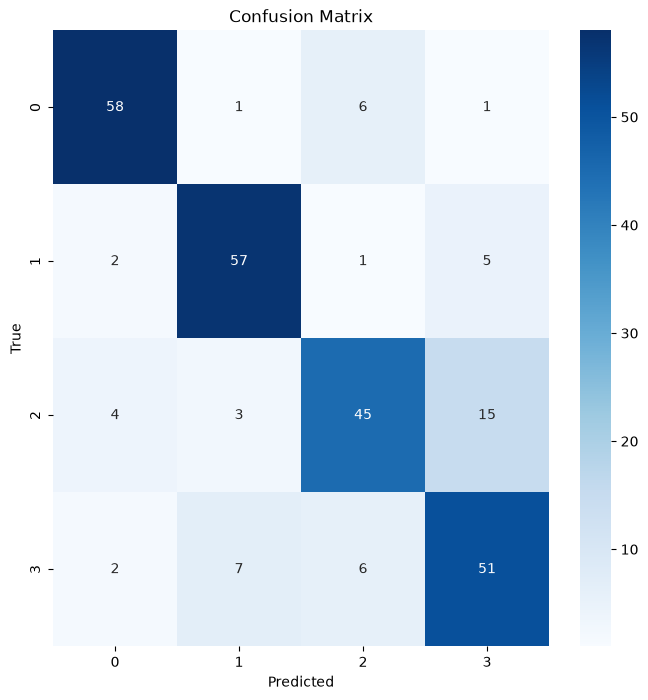


Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.88      0.88        66
           1       0.84      0.88      0.86        65
           2       0.78      0.67      0.72        67
           3       0.71      0.77      0.74        66

    accuracy                           0.80       264
   macro avg       0.80      0.80      0.80       264
weighted avg       0.80      0.80      0.80       264



In [24]:
# =============================================================================
# Konfusionsmatrix + Klassifizierungsreport
# Für die abschließende Bewertung nimm test_dataset. Der Trainingsdatensatz ist
# zum Lernen da; validation_dataset nutzt du während des Trainings zum 
# Vergleichen und Abstimmen des Modells. Den Testdatensatz solltest du erst 
# nach der Modellwahl auswerten.
# =============================================================================
# Daten aus Validation/Test holen
y_true = []
y_pred = []

for images, labels in test_dataset:               # Get predictions & gt
    preds = model.predict(images)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)
print("Shapes of y_true and _pred:", y_true.shape, y_pred.shape)

print("Classes:", class_names)                          # Class list

cm = confusion_matrix(y_true, y_pred)                   # Confusion Matrix

plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# Classification Report
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

In [25]:
print("True labels:", np.bincount(y_true, minlength=len(class_names)))
print("Predictions:", np.bincount(y_pred, minlength=len(class_names)))

True labels: [66 65 67 66]
Predictions: [66 68 58 72]


In [26]:
# Example image from the test set; change this path to use another image.
image_path = Path(dataset_for_training_split) / "test" / "0" / "14.png"
img_pred_bgr = cv2.imread(str(image_path))
if img_pred_bgr is None:
    raise FileNotFoundError(f"Image not found or unreadable: {image_path}")

# image_dataset_from_directory loads RGB images; OpenCV reads BGR by default.
img_pred = cv2.cvtColor(img_pred_bgr, cv2.COLOR_BGR2RGB)
img_pred = cv2.resize(img_pred, (IMG_WIDTH, IMG_HEIGHT))

# The model already applies Rescaling(1./255), so keep pixel values in [0, 255].
data_pred = np.expand_dims(img_pred.astype(np.float32), axis=0)
result = model.predict(data_pred, verbose=0)

symbol_names = {
    "0": "Cross",
    "1": "Circle",
    "2": "Triangle",
    "3": "Square",
}

print("Probability for classes:")
for class_name, probability in zip(class_names, result[0]):
    print(f"{symbol_names[class_name]}: {probability * 100:.2f}%")

Probability for classes:
Cross: 100.00%
Circle: 0.00%
Triangle: 0.00%
Square: 0.00%


In [27]:
# =============================================================================
# Output class: 
# Translate the predicted class label (0, 1, 2, 3) to its symbol.
# =============================================================================

predicted_index = int(np.argmax(result[0]))
predicted_class = class_names[predicted_index]
predicted_symbol = symbol_names[predicted_class]
print(f"{predicted_symbol} detected! (class {predicted_class})")

Cross detected! (class 0)


In [28]:
import gc
from tensorflow.keras import backend as K

del model
del history
del train_dataset
del validation_dataset
del test_dataset

K.clear_session()
gc.collect()

0

In [29]:
import ctypes
libc = ctypes.CDLL("libc.so.6")
libc.malloc_trim(0)
gc.collect()

0